In [1]:
MODEL_CODE = "rf"
MODEL_NAME = "Random Forest"

# 07: Random Forest Modeli

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini · **Model ailesi:** ağaç / bagging

**Random Forest**, çok sayıda Decision Tree'nin oylarını birleştirir (bagging). Her ağaç eğitim verisinden rastgele çekilen farklı bir örneklemle (bootstrap) eğitilir ve her bölmede sütunların yalnızca rastgele bir alt kümesine bakar. Böylece ağaçlar birbirinden farklı hatalar yapar; ortalamaları alındığında tek ağacın iki zayıflığı azalır: ezberleme (overfitting) ve verideki küçük değişikliklere karşı kararsızlık. Bedeli, modelin tek bir ağaç gibi doğrudan okunamamasıdır; kararları SHAP ve LIME ile açıklanır.

**Model neyi kendisi öğrenir, neyi biz seçeriz?** Ağaçların hangi sütunda hangi eşikle bölüneceğini model eğitimde kendisi bulur. Ağaçların ne kadar derinleşeceği, bir yaprakta en az kaç kişi kalacağı, her bölmede kaç sütuna bakılacağı ve dengesizliğin nasıl giderileceği ise eğitimden önce verilen ayarlardır (hiperparametre). Bunlar GridSearch ile, ortak CV katları üzerinde seçilir.

**Bu notebook'ta yapılanlar:** hiperparametre ve dengeleme araması · derinliğin overfitting'e etkisi · feature engineering'in etkisi · final modelin CV değerlendirmesi, eşik seçimi, öğrenme eğrisi · test seti · Decision Tree ile karşılaştırma · XAI (SHAP + LIME)

**Colab'da çalıştırmak için:** Sol menüdeki klasör simgesinden `train.csv`, `test.csv`, `config.py`, `preprocessing.py`, `metrics.py` ve `explain.py` dosyalarını yükleyin. Decision Tree ile karşılaştırma için `07_model_dt` notebook'unun çıktıları (`results.csv`, `dt.joblib`) da gerekir; yoksa o bölüm atlanır.

## 1. Kurulum

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime

/Users/Sude/Documents/GitHub/stroke_detection_ML/test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

# Output folders: models/ and figures/ at the repo root (the working directory on Colab)
ROOT = SRC_DIR.resolve().parent if SRC_DIR.resolve().name == "src" else Path(".")
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)

import time
import warnings

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV

from config import MAIN_METRIC, RANDOM_STATE, RESULTS_FILE
from explain import explain
from metrics import (SCORING, compare_models, cv_evaluate, learning_curve_analysis, plot_curves,
                     predict_score, shared_cv, test_evaluate, threshold_analysis)
from preprocessing import build_pipeline, load_data

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

## 2. Veri

`train.csv` / `test.csv`. Ön işleme (feature engineering, encoding, ölçekleme, SMOTE) `build_pipeline()` içinde yapılır; test seti en sona kadar kullanılmaz.

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, f"| inme: {y_train.sum()} kişi ({y_train.mean():.2%})")
print("Test:  ", X_test.shape, f"| inme: {y_test.sum()} kişi ({y_test.mean():.2%})")

Eğitim: (3521, 17) | inme: 306 kişi (8.69%)
Test:   (881, 17) | inme: 77 kişi (8.74%)


## 3. Hiperparametre ve dengeleme araması

Bu bölüm, final modelin ayarlarına adım adım nasıl varıldığını gösterir: önce hiçbir ayar yapılmamış **varsayılan model** ölçülür, sonra ayarlar aranır, sonra her ayarın tek başına etkisi tablo ve grafikle gösterilir. Seçim bir alışkanlığa değil, bu karşılaştırmalara dayanır.

| Parametre | Denenen değerler | Anlamı |
|---|---|---|
| `n_estimators` | 300 (sabit) | Ağaç sayısı. Ağaç eklemek overfitting'e yol açmaz, yalnızca sonucu kararlı hale getirir ve süreyi uzatır; bu yüzden aranmaz |
| `max_depth` | 2, 3, 4, 6, 8, 12, None | Her ağacın en fazla kaç seviye derinleşeceği. `None` sınırsız demektir. İlk aramada en küçük değer 4'tü ve seçilen değer buydu; aralık, optimumun kenarda kalıp kalmadığını görmek için 2 ve 3'e kadar genişletildi |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80, 160 | Bir yaprakta en az kaç kişi kalacağı. Büyük değer, tek tük hastaya özel kural öğrenilmesini engeller. İlk aramada en büyük değer 20'ydi; 40 en iyi çıkıp kenarda kaldığı için 80 ve 160 eklendi |
| `max_features` | sqrt, 0.5 | Her bölmede bakılan sütun oranı. Küçük değer ağaçları birbirinden daha farklı yapar |
| dengeleme | yok, SMOTE, class_weight (balanced), class_weight (balanced_subsample) | SMOTE azınlık sınıfı için sentetik hasta üretir. class_weight veri üretmez, inme vakalarındaki hatayı daha ağır cezalandırır; `balanced_subsample` bu ağırlığı her ağacın kendi örneklemine göre yeniden hesaplar. "Yok" kolu, dengelemenin gerçekten gerekli olup olmadığını gösteren referanstır |

SMOTE'lu satırlarda pipeline'ın `balance` adımı SMOTE, diğerlerinde bu adım boştur (`passthrough`). 4 × 7 × 7 × 2 = 392 kombinasyonun tamamı aynı CV katları (`shared_cv()`) ve aynı metriklerle (`SCORING`) karşılaştırılır; en iyi model `MAIN_METRIC` (PR-AUC) ile seçilir.

**Not (std):** Bu bölümdeki "± std" değerleri 5 katın PR-AUC'sinin standart sapmasıdır (`cv_evaluate` ile aynı tanım). Bir farkın gerçek olup olmadığına bu sapmayla bakılır.

In [5]:
import numpy as np
from config import CV_FOLDS

STD_FIX = (CV_FOLDS / (CV_FOLDS - 1)) ** 0.5   # GridSearch std is ddof=0; cv_evaluate uses ddof=1


def balancing_name(balance, class_weight):
    if "SMOTE" in str(balance):
        return "smote"
    return "yok" if pd.isna(class_weight) else f"class_weight ({class_weight})"


def search_table(search, hyper):
    """Every candidate of the search: fold mean and std of the metrics (std with ddof=1, like cv_evaluate)."""
    r = pd.DataFrame(search.cv_results_)
    t = pd.DataFrame({"dengeleme": [balancing_name(b, w) for b, w in
                                    zip(r["param_balance"], r["param_model__class_weight"])]})
    for h in hyper:
        t[h] = r[f"param_model__{h}"].map(str).values   # None stays as "None"
    t["pr_auc_cv"] = r["mean_test_pr_auc"].values
    t["pr_auc_std"] = r["std_test_pr_auc"].values * STD_FIX
    for m in ["recall", "precision", "f1", "roc_auc"]:
        t[f"{m}_cv"] = r[f"mean_test_{m}"].values
    t["pr_auc_train"] = r["mean_train_pr_auc"].values
    t["fark (train - cv)"] = t["pr_auc_train"] - t["pr_auc_cv"]
    return t.sort_values("pr_auc_cv", ascending=False, kind="mergesort").reset_index(drop=True)


def cv_row(label, pipe):
    """One-row summary of a pipeline on the shared CV folds (threshold 0.5, not written to results.csv)."""
    s = cv_evaluate(pipe, X_train, y_train, model_name=label, save=False, verbose=False)["summary"]
    row = {"model": label, "pr_auc (CV ± std)": f"{s.loc['pr_auc', 'cv_mean']:.3f} ± {s.loc['pr_auc', 'cv_std']:.3f}"}
    for m in ["recall", "precision", "f1", "roc_auc"]:
        row[m] = s.loc[m, "cv_mean"]
    row["pr_auc_train"] = s.loc["pr_auc", "train_mean"]
    return row


def one_at_a_time(full, col):
    """Values of one hyperparameter, all the others fixed at the best candidate's values."""
    others = [c for c in HYPER if c != col]
    mask = (full[others] == full.loc[0, others]).all(axis=1)
    return full[mask].set_index(col).loc[GRID_ORDER[col]]


def show_param_table(sub, col, best_value):
    d = pd.DataFrame({
        "pr_auc (CV ± std)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(sub["pr_auc_cv"], sub["pr_auc_std"])],
        "recall": sub["recall_cv"], "precision": sub["precision_cv"], "f1": sub["f1_cv"],
        "fark (train - cv)": sub["fark (train - cv)"],
    }, index=sub.index).round(3)
    d.index.name = col
    d["seçilen"] = ["◄" if v == best_value else "" for v in d.index]
    display(d)

### 3.1 Başlangıç noktası: varsayılan model

Hiçbir ayar yapılmamış `RandomForestClassifier()` (sklearn varsayılanı: 100 ağaç, sınırsız derinlik, `max_features="sqrt"`), aynı ön işleme hattı ve aynı CV katlarıyla ölçülür. Ayarlanmış modelin değeri bu çizgiyle karşılaştırıldığında anlaşılır. İki satır var: dengelemesiz (saf varsayılan) ve SMOTE'lu. Eşik 0,5'tir; recall / precision / F1 bu eşikteki değerlerdir.

In [6]:
baseline = pd.DataFrame([
    cv_row("Varsayılan, dengeleme yok", build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), balancing="none")),
    cv_row("Varsayılan + SMOTE", build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), balancing="smote")),
]).set_index("model")
baseline_pr_auc = float(baseline.iloc[0]["pr_auc (CV ± std)"].split(" ± ")[0])
baseline.round(3)

,pr_auc (CV ± std),recall,precision,f1,roc_auc,pr_auc_train
model,,,,,,
"Varsayılan, dengeleme yok",0.169 ± 0.015,0.003,0.100,0.006,0.669,1.0
Varsayılan + SMOTE,0.165 ± 0.020,0.118,0.196,0.147,0.689,1.0


### 3.2 GridSearch

392 kombinasyonun hepsi aranır. En iyi kombinasyon PR-AUC ortalamasına göre seçilir.

In [7]:
forest_grid = {
    "max_depth": [2, 3, 4, 6, 8, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80, 160],
    "max_features": ["sqrt", 0.5],
}
forest_params = {f"model__{k}": v for k, v in forest_grid.items()}
params = [
    {**forest_params, "balance": [SMOTE(random_state=RANDOM_STATE)], "model__class_weight": [None]},
    {**forest_params, "balance": ["passthrough"], "model__class_weight": ["balanced", "balanced_subsample", None]},
]
HYPER = ["dengeleme", "max_depth", "min_samples_leaf", "max_features"]
NUMERIC_HYPER = ["max_depth", "min_samples_leaf"]
GRID_ORDER = {"dengeleme": ["yok", "smote", "class_weight (balanced)", "class_weight (balanced_subsample)"],
              **{k: [str(v) for v in vals] for k, vals in forest_grid.items()}}

start = time.time()
forest = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)
search = GridSearchCV(build_pipeline(forest, balancing="smote"), params, cv=shared_cv(), scoring=SCORING,
                      refit=MAIN_METRIC, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
best = search.best_estimator_   # the pipeline itself, not the search object
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items() if k.startswith("model__")}
chosen_balancing = balancing_name(search.best_params_["balance"], best_params["class_weight"])

full = search_table(search, ["max_depth", "min_samples_leaf", "max_features"])
assert abs(full.loc[0, "pr_auc_cv"] - search.best_score_) < 1e-9

print(f"Süre: {time.time() - start:.0f} sn | {len(full)} kombinasyon")
print("Seçilen dengeleme:", chosen_balancing)
print("En iyi parametreler:", best_params)
print(f"En iyi CV {MAIN_METRIC} (kat ortalaması): {search.best_score_:.4f} ± {full.loc[0, 'pr_auc_std']:.4f}")

Süre: 246 sn | 392 kombinasyon
Seçilen dengeleme: yok
En iyi parametreler: {'class_weight': None, 'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 40}
En iyi CV pr_auc (kat ortalaması): 0.2214 ± 0.0327


### 3.3 Tüm sonuçlar

İlk 15 kombinasyon aşağıdadır; 392 kombinasyonun tamamı `figures/rf_grid_results.csv` dosyasına yazılır. Ardından seçilen değerlerin arama aralığında nerede durduğu (kenarda mı, içte mi) ve en iyi adayın bir standart sapması içinde kaç adayın kaldığı yazdırılır: bu sayı büyükse seçimin gürültüyle ayırt edilemeyen alternatifleri çoktur.

In [8]:
full.round(4).to_csv(FIG_DIR / f"{MODEL_CODE}_grid_results.csv", index=False)
display(full.head(15).round(4))

best_row = full.loc[0]
for col in NUMERIC_HYPER:
    order = GRID_ORDER[col]
    i = order.index(best_row[col])
    where = "KENARDA" if i in (0, len(order) - 1) else "iç noktada"
    print(f"{col}: seçilen {best_row[col]} ({where}); denenen: {', '.join(order)}")

within = full[full["pr_auc_cv"] >= full.loc[0, "pr_auc_cv"] - full.loc[0, "pr_auc_std"]]
print(f"\nEn iyi adayın bir standart sapma altındaki aday sayısı: {len(within)} / {len(full)} "
      f"(sınır: {full.loc[0, 'pr_auc_cv'] - full.loc[0, 'pr_auc_std']:.3f})")
for col in HYPER:
    print(f"  {col}: {dict(within[col].value_counts())}")

,dengeleme,max_depth,min_samples_leaf,max_features,pr_auc_cv,pr_auc_std,recall_cv,precision_cv,f1_cv,roc_auc_cv,pr_auc_train,fark (train - cv)
0,yok,3,40,sqrt,0.2214,0.0327,0.0000,0.0000,0.0000,0.7116,0.2419,0.0205
1,yok,2,5,sqrt,0.2160,0.0303,0.0000,0.0000,0.0000,0.7120,0.2410,0.0250
2,yok,2,40,sqrt,0.2157,0.0298,0.0000,0.0000,0.0000,0.7117,0.2303,0.0147
3,class_weight (balanced),3,1,sqrt,0.2157,0.0311,0.5981,0.1513,0.2414,0.7114,0.2761,0.0604
4,yok,3,20,sqrt,0.2155,0.0282,0.0000,0.0000,0.0000,0.7114,0.2582,0.0427
5,yok,2,20,sqrt,0.2153,0.0305,0.0000,0.0000,0.0000,0.7119,0.2371,0.0218
6,class_weight (balanced_subsample),2,10,0.5,0.2147,0.0280,0.6046,0.1546,0.2460,0.7167,0.2323,0.0176
7,class_weight (balanced),3,5,sqrt,0.2146,0.0299,0.6014,0.1526,0.2433,0.7114,0.2719,0.0573
8,class_weight (balanced_subsample),2,5,0.5,0.2138,0.0269,0.6046,0.1545,0.2458,0.7166,0.2324,0.0186
9,class_weight (balanced_subsample),2,1,0.5,0.2138,0.0269,0.6046,0.1546,0.2460,0.7166,0.2324,0.0186


max_depth: seçilen 3 (iç noktada); denenen: 2, 3, 4, 6, 8, 12, None
min_samples_leaf: seçilen 40 (iç noktada); denenen: 1, 5, 10, 20, 40, 80, 160

En iyi adayın bir standart sapma altındaki aday sayısı: 316 / 392 (sınır: 0.189)
  dengeleme: {'yok': np.int64(89), 'class_weight (balanced)': np.int64(85), 'class_weight (balanced_subsample)': np.int64(83), 'smote': np.int64(59)}
  max_depth: {'4': np.int64(56), '3': np.int64(55), '2': np.int64(49), '6': np.int64(48), '8': np.int64(41), 'None': np.int64(34), '12': np.int64(33)}
  min_samples_leaf: {'80': np.int64(56), '160': np.int64(53), '40': np.int64(52), '20': np.int64(50), '10': np.int64(43), '5': np.int64(32), '1': np.int64(30)}
  max_features: {'sqrt': np.int64(168), '0.5': np.int64(148)}


### 3.4 Her hiperparametrenin tek başına etkisi

Her tabloda yalnız bir hiperparametre değişir, diğerleri en iyi kombinasyondaki değerinde sabit kalır. Grafikte nokta ortalama, çubuk ± std'dir; kesik çizgi varsayılan modelin (dengelemesiz) CV PR-AUC'sidir. Isı haritası derinlik ve yaprak büyüklüğünü birlikte gösterir.


dengeleme:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
dengeleme,,,,,,
yok,0.221 ± 0.033,0.000,0.000,0.000,0.020,◄
smote,0.195 ± 0.026,0.556,0.152,0.239,0.045,
class_weight (balanced),0.212 ± 0.033,0.595,0.149,0.238,0.033,
class_weight (balanced_subsample),0.213 ± 0.030,0.572,0.152,0.240,0.036,



max_depth:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
max_depth,,,,,,
2,0.216 ± 0.030,0.0,0.0,0.0,0.015,
3,0.221 ± 0.033,0.0,0.0,0.0,0.020,◄
4,0.208 ± 0.022,0.0,0.0,0.0,0.056,
6,0.211 ± 0.020,0.0,0.0,0.0,0.087,
8,0.203 ± 0.022,0.0,0.0,0.0,0.107,
12,0.206 ± 0.019,0.0,0.0,0.0,0.107,
None,0.206 ± 0.019,0.0,0.0,0.0,0.107,



min_samples_leaf:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
min_samples_leaf,,,,,,
1,0.210 ± 0.026,0.0,0.0,0.0,0.081,
5,0.209 ± 0.027,0.0,0.0,0.0,0.068,
10,0.213 ± 0.026,0.0,0.0,0.0,0.056,
20,0.215 ± 0.028,0.0,0.0,0.0,0.043,
40,0.221 ± 0.033,0.0,0.0,0.0,0.020,◄
80,0.209 ± 0.024,0.0,0.0,0.0,0.022,
160,0.197 ± 0.016,0.0,0.0,0.0,0.019,



max_features:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
max_features,,,,,,
sqrt,0.221 ± 0.033,0.0,0.0,0.0,0.020,◄
0.5,0.211 ± 0.019,0.0,0.0,0.0,0.042,


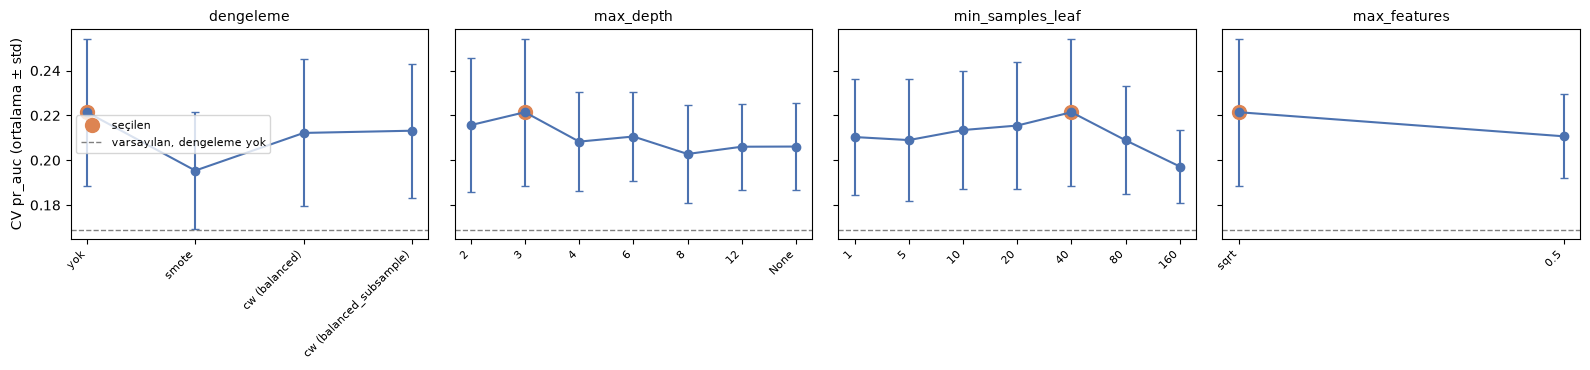

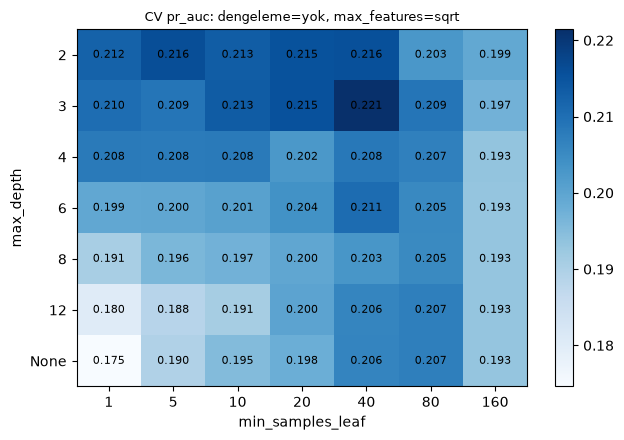

In [9]:
for col in HYPER:
    print(f"\n{col}:")
    show_param_table(one_at_a_time(full, col), col, full.loc[0, col])

fig, axes = plt.subplots(1, len(HYPER), figsize=(4 * len(HYPER), 3.8), sharey=True)
for ax, col in zip(axes, HYPER):
    sub = one_at_a_time(full, col)
    x = range(len(sub))
    ax.errorbar(x, sub["pr_auc_cv"], yerr=sub["pr_auc_std"], fmt="o-", color="#4C72B0", capsize=3)
    i = list(sub.index).index(full.loc[0, col])
    ax.plot(i, sub["pr_auc_cv"].iloc[i], "o", color="#DD8452", markersize=10, label="seçilen")
    ax.axhline(baseline_pr_auc, color="gray", linestyle="--", linewidth=1, label="varsayılan, dengeleme yok")
    ax.set_xticks(list(x))
    ax.set_xticklabels([s.replace("class_weight ", "cw ") for s in sub.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(col, fontsize=10)
axes[0].set_ylabel(f"CV {MAIN_METRIC} (ortalama ± std)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_param_effects.png", dpi=200)
plt.show()

# depth x min_samples_leaf, the other hyperparameters fixed at the best values
others = [c for c in HYPER if c not in ("max_depth", "min_samples_leaf")]
sub = full[(full[others] == full.loc[0, others]).all(axis=1)]
grid = (sub.pivot(index="max_depth", columns="min_samples_leaf", values="pr_auc_cv")
        .loc[GRID_ORDER["max_depth"], GRID_ORDER["min_samples_leaf"]])
fig, ax = plt.subplots(figsize=(1 + 0.8 * grid.shape[1], 1 + 0.5 * grid.shape[0]))
im = ax.imshow(grid.values.astype(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
for (i, j), v in __import__("numpy").ndenumerate(grid.values.astype(float)):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title(f"CV {MAIN_METRIC}: {', '.join(f'{c}={full.loc[0, c]}' for c in others)}", fontsize=9)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_depth_leaf_heatmap.png", dpi=200)
plt.show()

### 3.5 Derinliğin etkisi (overfitting)

Her derinlik için, her dengeleme kolunda en iyi `min_samples_leaf` / `max_features` seçilerek eğitim ve CV skorları çizilir. Derinlik arttıkça eğitim skoru yükselir. CV skoru da yükselmiyorsa fazladan derinlik yalnızca ezberlemedir. Decision Tree'nin aynı grafiğiyle karşılaştırıldığında, ağaçların ortalamasını almanın etkisi görülür. CV farklarının çoğu fold std'si içinde kalır; grafiği okurken bunu hesaba katın.

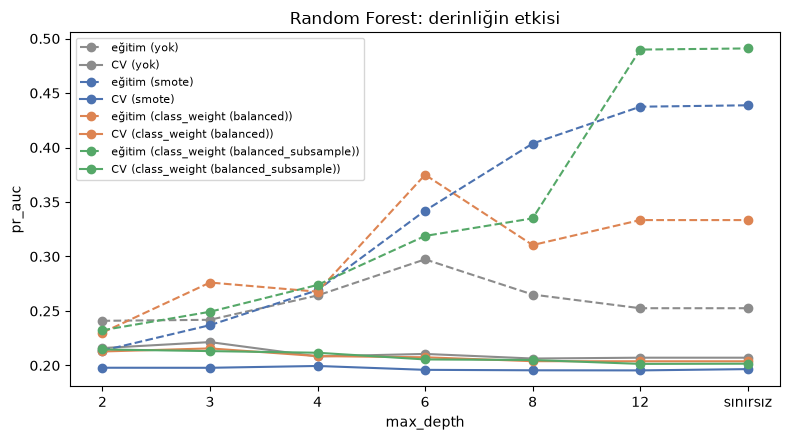

In [10]:
r = full.copy()
r["max_depth"] = r["max_depth"].replace("None", "sınırsız")
order = GRID_ORDER["max_depth"][:-1] + ["sınırsız"]
colors = {"yok": "#8C8C8C", "smote": "#4C72B0", "class_weight (balanced)": "#DD8452",
          "class_weight (balanced_subsample)": "#55A868"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for bal, color in colors.items():
    sub = (r[r["dengeleme"] == bal].sort_values("pr_auc_cv", ascending=False)
           .drop_duplicates("max_depth").set_index("max_depth").loc[order])
    ax.plot(order, sub["pr_auc_train"], "o--", color=color, label=f"eğitim ({bal})")
    ax.plot(order, sub["pr_auc_cv"], "o-", color=color, label=f"CV ({bal})")
ax.set_xlabel("max_depth")
ax.set_ylabel(MAIN_METRIC)
ax.set_title("Random Forest: derinliğin etkisi")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_depth_overfitting.png", dpi=200)
plt.show()

### 3.6 Varsayılan model ve seçilen model yan yana

Seçilen model aynı pipeline ve aynı CV katlarıyla yeniden ölçülür (PR-AUC grid'deki değerle aynı çıkmalıdır).

In [11]:
tuned_label = (f"Seçilen ({chosen_balancing}, derinlik {best_params['max_depth']}, yaprak {best_params['min_samples_leaf']}, "
               f"{best_params['max_features']})")
compare = pd.concat([baseline, pd.DataFrame([cv_row(tuned_label, best)]).set_index("model")])
compare.round(3)

,pr_auc (CV ± std),recall,precision,f1,roc_auc,pr_auc_train
model,,,,,,
"Varsayılan, dengeleme yok",0.169 ± 0.015,0.003,0.100,0.006,0.669,1.000
Varsayılan + SMOTE,0.165 ± 0.020,0.118,0.196,0.147,0.689,1.000
"Seçilen (yok, derinlik 3, yaprak 40, sqrt)",0.221 ± 0.033,0.000,0.000,0.000,0.712,0.242


### 3.7 Karar

- **Başlangıç noktasına göre kazanç.** Varsayılan Random Forest (100 ağaç, sınırsız derinlik) eğitim verisini ezberler (eğitim PR-AUC 1,00) ve CV PR-AUC'si 0,169 ± 0,015'tir; SMOTE'lu varsayılan 0,165 ± 0,020. Seçilen model 0,221 ± 0,033'e (ROC-AUC 0,712, varsayılan 0,669) çıkar. Kazanç 0,05 civarındadır; bu, seçilen modelin std'sinden (0,033) büyük ama tek bir 5 katlı bölmeye dayanan bir farktır.
- **Seçilen model:** dengeleme yok, `max_depth=3`, `min_samples_leaf=40`, `max_features="sqrt"` (300 ağaç). Önceki aramada seçilen model `balanced_subsample`, derinlik 4, yaprak 10, sqrt idi. İlk aramada derinlik 4 aralığın en küçük değeriydi; 2 ve 3 eklenince optimum içeri alındı (3 seçildi, 2 daha düşük: 0,216). Yaprak 40 da ilk aramada kenardaydı; 80 ve 160 eklendi, ikisi de daha düşük (0,209 ve 0,197), yani optimum artık iç noktadadır.
- **`max_depth`:** 2: 0,216, 3: 0,221, 4: 0,208, 6: 0,211, 8: 0,203, 12 ve sınırsız: 0,206 (std 0,02-0,03). Sığ ağaçlar yalnızca biraz daha iyidir ve fark std içindedir; ama derinlik arttıkça eğitim-CV farkı 0,015'ten 0,107'ye çıkar. Yani derin ağaçlar CV'de kazanç sağlamadan daha çok ezberler; bu yüzden sığ olan seçildi.
- **`min_samples_leaf`:** 1: 0,210, 5: 0,209, 10: 0,213, 20: 0,215, 40: 0,221, 80: 0,209, 160: 0,197. Tepe 40'tadır, ama 10-40 arası std içinde birbirine yakındır.
- **`max_features`:** sqrt 0,221 ± 0,033, 0,5: 0,211 ± 0,019; fark std içindedir.
- **Dengeleme:** yok 0,221, `balanced_subsample` 0,213, `balanced` 0,212, SMOTE 0,195 ± 0,026 (diğer ayarlar en iyi değerinde sabit). Yok / class_weight arasındaki fark std içindedir; SMOTE geridedir. Önceki "class_weight sentetik hastadan daha iyi" bulgusu SMOTE için doğrulandı, ama "class_weight dengelemesizden iyi" bulgusu desteklenmedi: PR-AUC eşikten bağımsız sıralama ölçüsüdür ve dengelemesiz model onu en az onun kadar iyi sağlar. Dengelemesiz modelin 0,5 eşiğinde recall'u 0'dır; bu yüzden eşik bölüm 6'da OOF tahminleriyle ayrıca seçilir.
- **Dürüstlük notu:** En iyi adayın bir standart sapması içinde 392 adayın 316'sı kalıyor. Yani Random Forest bu veride ayarlara karşı duyarsızdır; seçilen nokta, benzer sonuç veren geniş bir bölgenin içinden en basit ve eğitim-CV farkı en küçük olandır.

## 4. Feature engineering'in etkisi

Ortak pipeline 5 yeni özellik ekler (17 → 28 sütun). Türetilen özelliklerin katkı sağlayıp sağlamadığı en iyi parametrelerle kontrol edilir (bu deneyler `results.csv`'ye yazılmaz).

In [12]:
rows = {}
for fe in [True, False]:
    pipe = build_pipeline(forest, balancing="smote", feature_engineering=fe)
    pipe.set_params(**search.best_params_)
    res = cv_evaluate(pipe, X_train, y_train, model_name=f"{MODEL_NAME} (FE={fe})", save=False, verbose=False)
    rows["FE açık" if fe else "FE kapalı"] = res["summary"]["cv_mean"]
pd.DataFrame(rows).T.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
FE açık,0.0,0.0,0.0,1.0,0.712,0.221,0.913
FE kapalı,0.0,0.0,0.0,1.0,0.718,0.212,0.913


## 5. Final model: CV değerlendirmesi

Seçilen model ortak `cv_evaluate` ile değerlendirilir ve sonucu `results.csv`'ye **bir satır** olarak eklenir. Karşılaştırma notebook'u bu satırı kullanır. Eğitim ve CV skorları arasındaki fark (`gap`) overfitting göstergesidir.

In [13]:
cv_result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME,
                        note=f"{chosen_balancing} + RF, GridSearch: {best_params}")

# Two CV PR-AUC numbers exist: the mean of the 5 fold scores (the table above, as in GridSearch)
# and one PR-AUC over all out-of-fold predictions pooled together (used for the threshold).
pooled = average_precision_score(cv_result["y"], cv_result["oof_score"])
print(f"CV PR-AUC, kat ortalaması: {cv_result['summary'].loc['pr_auc', 'cv_mean']:.4f} | "
      f"birleşik OOF: {pooled:.4f}")

===== Random Forest: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.24 sn

             train_mean  cv_mean  cv_std   gap
metric                                        
recall            0.000    0.000   0.000  0.00
precision         0.000    0.000   0.000  0.00
f1                0.000    0.000   0.000  0.00
specificity       1.000    1.000   0.000  0.00
roc_auc           0.752    0.712   0.019  0.04
pr_auc            0.242    0.221   0.033  0.02
accuracy          0.913    0.913   0.001 -0.00

Sonuç 'results.csv' dosyasına eklendi.
CV PR-AUC, kat ortalaması: 0.2214 | birleşik OOF: 0.1904


## 6. Eşik seçimi

Varsayılan eşik 0.5'tir, ama inmeyi kaçırmak yanlış alarmdan pahalı olduğu için eşik, **test setine bakılmadan** CV tahminleri (OOF) üzerinde seçilir: hedef recall'u (%80) en az yanlış alarmla sağlayan eşik.

===== Random Forest: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     276      30          2155   0.902      0.114        0.330                612.042
      0.10     172     134           958   0.562      0.152        0.702                272.082
      0.15      81     225           309   0.265      0.208        0.904                 87.759
      0.20      42     264           102   0.137      0.292        0.968                 28.969
      0.25      22     284            43   0.072      0.338        0.987                 12.212
      0.30       0     306             5   0.000      0.000        0.998                  1.420
      0.35       0     306             0   0.000      0.000        1.000                  0.000
      0.40       0     306             0   0.000      0.000        1.000                  0.000
      0.45       0     306             0   0.000      0.000        

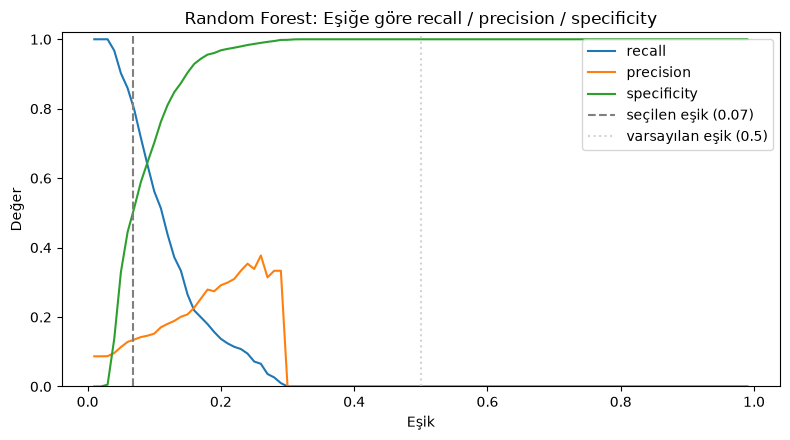

In [14]:
table, threshold = threshold_analysis(cv_result["y"], cv_result["oof_score"], model_name=MODEL_NAME)

## 7. Overfitting kontrolü: öğrenme eğrisi

Eğitim verisi büyüdükçe eğitim ve CV skorları birbirine yaklaşıyorsa model genelleşiyor demektir. Büyük ve kapanmayan bir fark overfitting, ikisinin birlikte düşük kalması underfitting gösterir.

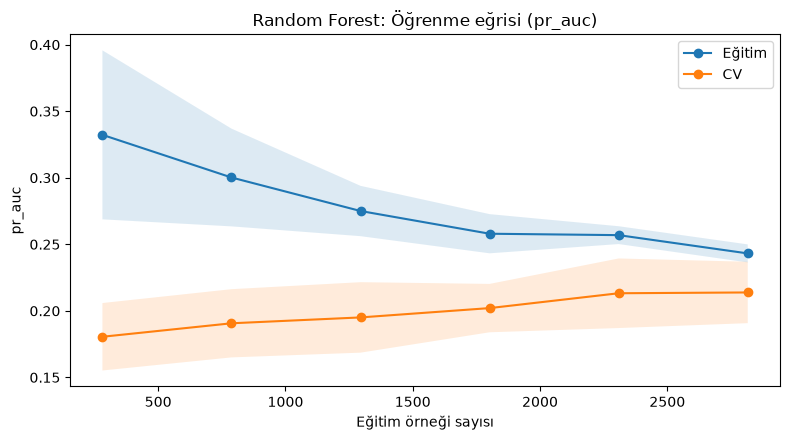

,train_size,train_mean,cv_mean,cv_std
0,281,0.332,0.181,0.025
1,788,0.300,0.191,0.026
2,1295,0.275,0.195,0.026
3,1802,0.258,0.202,0.018
4,2309,0.257,0.213,0.026
5,2816,0.243,0.214,0.023


In [15]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
lc.round(3)

## 8. Test seti (yalnızca bir kez)

Final model tüm eğitim verisiyle yeniden eğitilir, seçilen eşikle test setinde değerlendirilir ve `models/` klasörüne kaydedilir.

===== Random Forest: Test seti (eşik = 0.068) =====
67/77 inme yakalandı, 10 inme kaçırıldı, 376 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.801  0.870         -0.069
precision                0.132  0.151         -0.019
f1                       0.227  0.258         -0.031
specificity              0.500  0.532         -0.032
roc_auc                  0.707  0.766         -0.059
pr_auc                   0.190  0.237         -0.046
accuracy                 0.526  0.562         -0.036


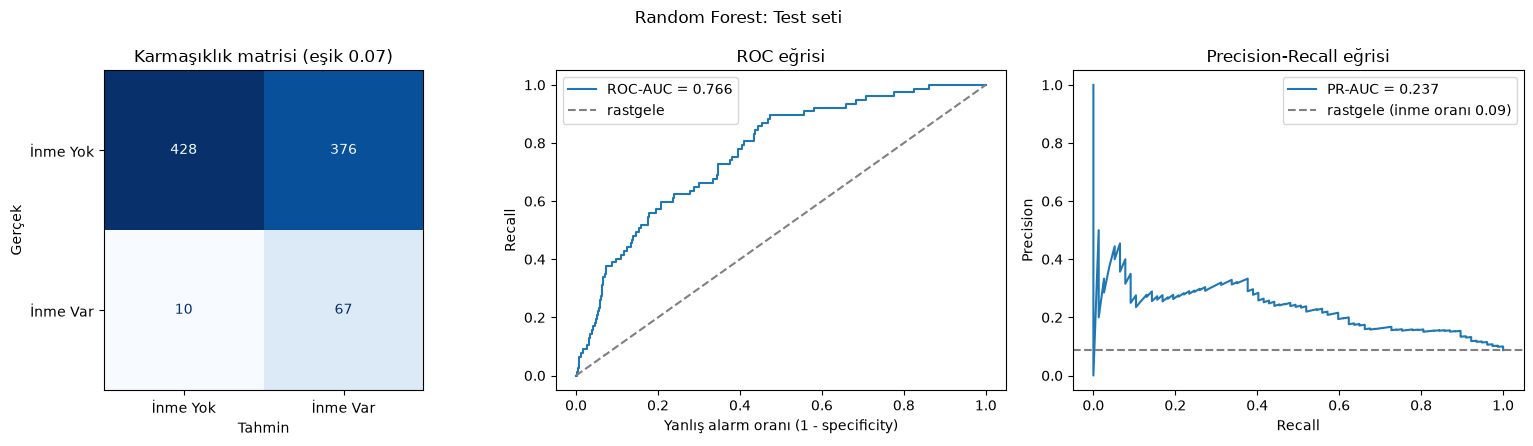

Model kaydedildi: models/rf.joblib


In [16]:
best.fit(X_train, y_train)
test_result = test_evaluate(best, X_test, y_test, threshold=threshold,
                            model_name=MODEL_NAME, cv_result=cv_result)

joblib.dump(best, MODEL_DIR / f"{MODEL_CODE}.joblib")
print(f"Model kaydedildi: models/{MODEL_CODE}.joblib")

## 9. Decision Tree ile karşılaştırma

Random Forest, Decision Tree'lerin birleşimi olduğu için ailenin asıl sorusu şudur: ağaçların ortalamasını almak tek ağaca göre ne kazandırıyor? CV sonuçları `results.csv`'den, test eğrileri iki kayıtlı modelden çizilir. `07_model_dt` çalıştırılmadıysa bu bölüm atlanır.

===== Model karşılaştırması (CV ortalaması ± std, pr_auc'e göre sıralı) =====
                  recall  precision         f1 specificity        roc_auc         pr_auc       accuracy  pr_auc_train_cv_gap  fit_time_s
model_name                                                                                                                              
Random Forest  0.0 ± 0.0  0.0 ± 0.0  0.0 ± 0.0   1.0 ± 0.0  0.712 ± 0.019  0.221 ± 0.033  0.913 ± 0.001                0.020        0.24
Decision Tree  0.0 ± 0.0  0.0 ± 0.0  0.0 ± 0.0   1.0 ± 0.0  0.689 ± 0.018    0.17 ± 0.01  0.913 ± 0.001                0.038        0.01


,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
model_name,,,,,,,
Decision Tree,0.0,0.0,0.0,1.0,0.689,0.170,0.913
Random Forest,0.0,0.0,0.0,1.0,0.712,0.221,0.913


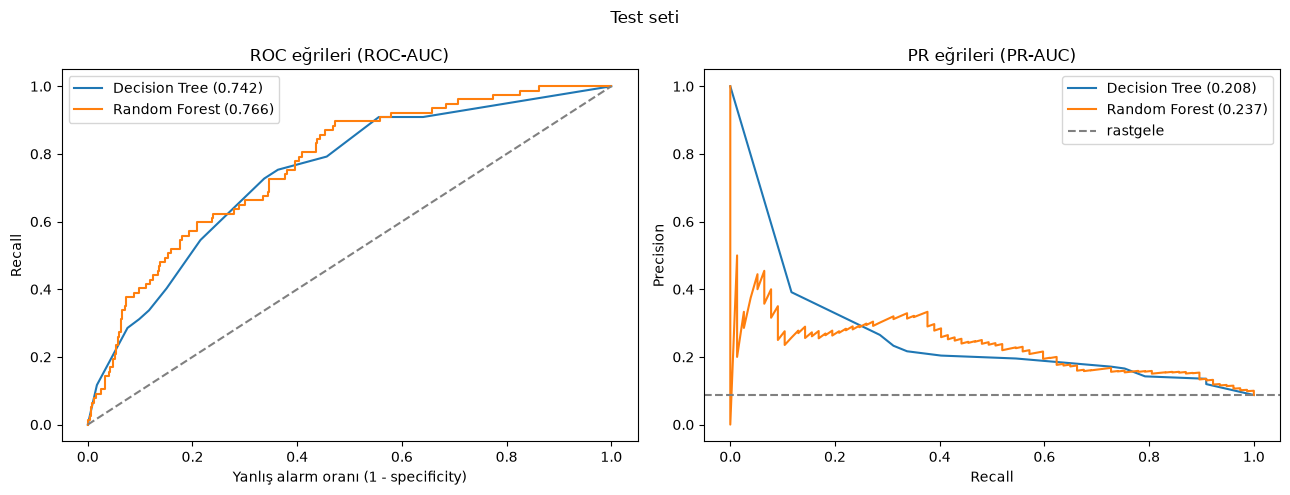

<Figure size 640x480 with 0 Axes>

In [17]:
dt_path = MODEL_DIR / "dt.joblib"
if dt_path.exists() and Path(RESULTS_FILE).exists():
    cv_table = compare_models(plot=False)
    display(cv_table.loc[[m for m in ["Decision Tree", MODEL_NAME] if m in cv_table.index]].round(3))

    dt = joblib.load(dt_path)
    plot_curves({"Decision Tree": (y_test, predict_score(dt, X_test)),
                 MODEL_NAME: (y_test, test_result["score"])}, title="Test seti")
    plt.gcf().savefig(FIG_DIR / "dt_rf_test_curves.png", dpi=200, bbox_inches="tight")
else:
    print("Decision Tree çıktıları bulunamadı, karşılaştırma atlandı.")

## 10. XAI: modelin açıklanması

Random Forest için ortak `explain()` fonksiyonu **TreeExplainer** kullanır: tüm test verisi açıklanır (300 ağaç olduğu için birkaç dakika sürebilir). Fonksiyona aramanın kendisi değil, `best` (pipeline) verilir.

**Grafik okuma:** Bar grafiğinde çubuk uzunluğu önemi gösterir. Özet grafiğinde kırmızı = özelliğin değeri yüksek, mavi = düşük; nokta sağdaysa inme riskini artırıyor. LIME'da yeşil çubuklar "inme var" kararını destekleyen koşullardır.

===== Random Forest: XAI Analizi =====


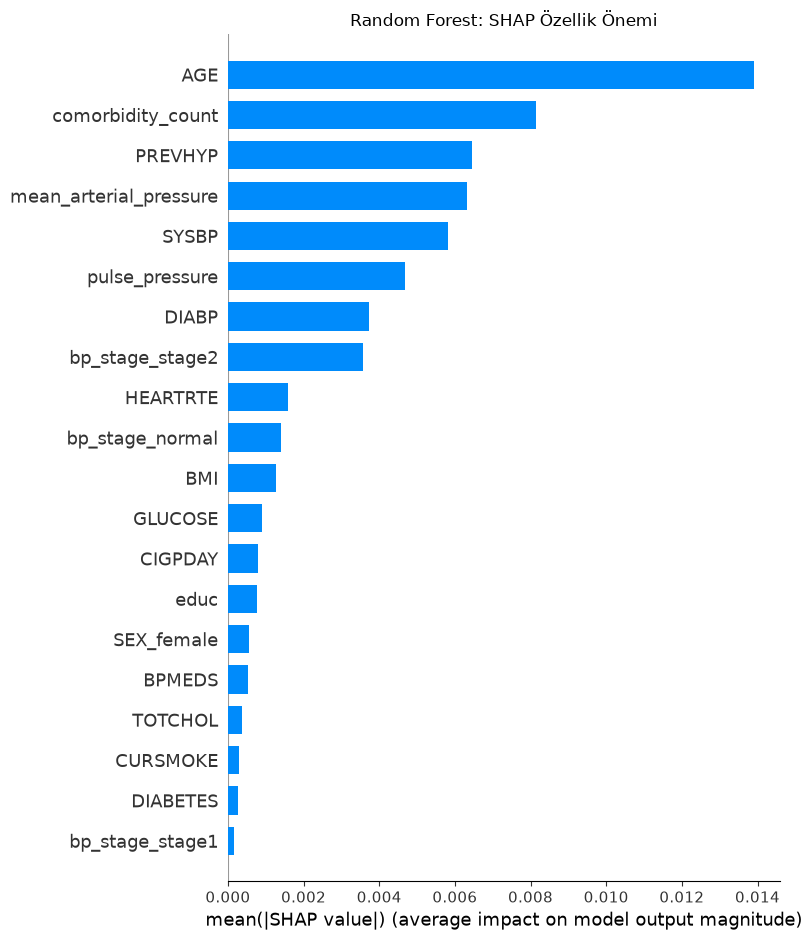

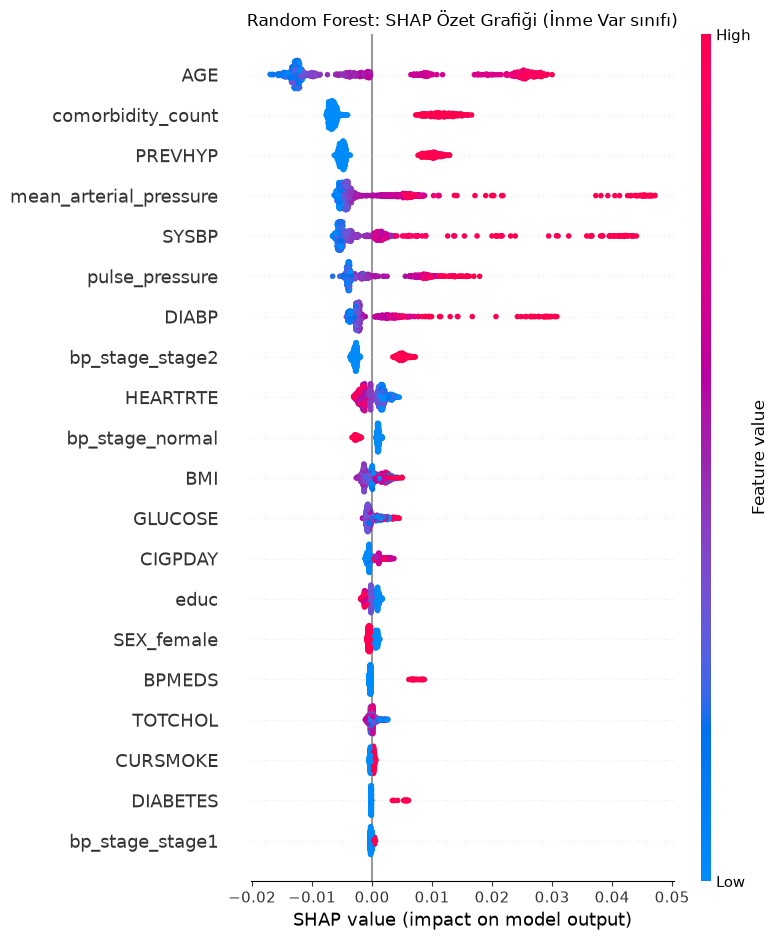


En önemli 5 özellik (SHAP):
               feature  mean_abs_shap
                   AGE       0.013896
     comorbidity_count       0.008156
               PREVHYP       0.006447
mean_arterial_pressure       0.006324
                 SYSBP       0.005806

[Random Forest] Test hastası #438: model risk skoru = 0.290


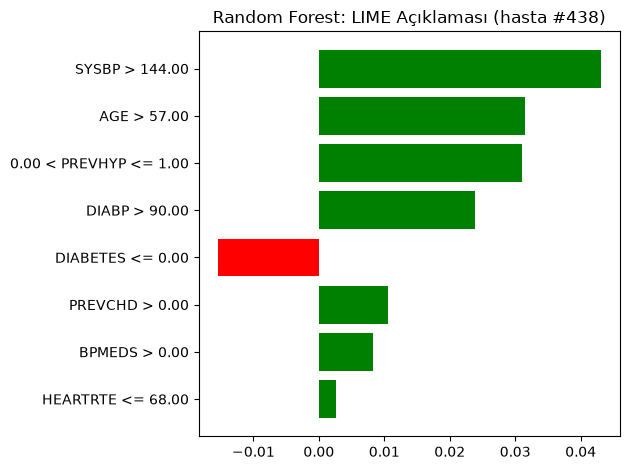


XAI süresi: 1 sn


In [18]:
# explain() shows its plots in order: SHAP bar, SHAP summary, LIME. Each one is also saved to figures/.
_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show
def _save_and_show(*args, **kwargs):
    name = next(_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show
try:
    start = time.time()
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME)
    print(f"\nXAI süresi: {time.time() - start:.0f} sn")
finally:
    plt.show = _show

In [19]:
xai["shap_importance"].head(10)

,feature,mean_abs_shap
0,AGE,0.013896
1,comorbidity_count,0.008156
2,PREVHYP,0.006447
3,mean_arterial_pressure,0.006324
4,SYSBP,0.005806
5,pulse_pressure,0.004670
6,DIABP,0.003737
7,bp_stage_stage2,0.003575
8,HEARTRTE,0.001585
9,bp_stage_normal,0.001407


## 11. Özet (rapor için)

### Neden Random Forest?

- **Tek ağacın zayıflıklarına çözüm:** Decision Tree okunabilir ama tek başına sınırlı kaldı (CV PR-AUC 0,170, ROC-AUC 0,69) ve verideki küçük değişikliklere duyarlıdır. Random Forest, farklı örneklemlerle ve her bölmede farklı sütun alt kümeleriyle eğitilen yüzlerce ağacın oylarını birleştirir. Ağaçların hataları birbirinden farklı olduğu için ortalamaları hem daha isabetli hem daha kararlıdır.
- **Tablo verisinde güçlü bir yöntem:** Ölçekleme gerektirmez, sayısal ve ikili sütunları birlikte kullanır, özellikler arasındaki etkileşimleri kendiliğinden yakalar. Bu tür sağlık verilerinde sık kullanılan, güvenilir bir karşılaştırma modelidir.
- **Açıklanabilirlik:** Tek ağaç gibi çizilerek okunamaz, ancak ağaç tabanlı olduğu için SHAP'ın hızlı ve kesin `TreeExplainer` yöntemiyle tüm test verisi açıklanabilir.


### Yöntem

- Ağaç sayısı 300'de sabitlendi (ağaç eklemek overfitting'e yol açmaz, yalnızca sonucu kararlı hale getirir). `max_depth`, `min_samples_leaf`, `max_features` ve dengeleme (yok, SMOTE, `class_weight="balanced"`, `class_weight="balanced_subsample"`) 392 kombinasyonluk bir GridSearch ile, ekibin ortak 5 katlı CV bölmesi üzerinde arandı; en iyi model PR-AUC ile seçildi. Aramadan önce varsayılan Random Forest aynı hat ve aynı katlarla ölçüldü; tüm adaylar `figures/rf_grid_results.csv` dosyasında.
- Bu özetteki CV PR-AUC değerleri, başka türlü belirtilmedikçe **5 katın skorlarının ortalamasıdır** (± katlar arası std). Eşik seçiminde kullanılan, tüm OOF tahminleri birleştirilerek hesaplanan PR-AUC ayrıdır (0,190).
- Seçilen model: **dengeleme yok, derinlik 3, yaprak başına en az 40 kişi, `sqrt`** (300 ağaç). Varsayılan model CV PR-AUC 0,169 ± 0,015 iken seçilen model 0,221 ± 0,033'tür. Hiperparametre farklarının çoğu fold std'si içindedir (392 adayın 316'sı en iyinin bir std'si içinde); belirgin olan tek şey sığ ağaçların (derinlik 2-3) eğitim-CV farkını küçültmesi ve SMOTE'un biraz geride kalmasıdır.
- Derinlik grafiği (`rf_depth_overfitting.png`): derinlik arttıkça eğitim skoru yükselir, CV skoru artmaz (sığ ağaçlarda 0,22, derinlerde 0,20-0,21 civarı).
- Feature engineering'in etkisi küçüktür: türetilen özelliklerle CV PR-AUC 0,221, onlarsız 0,212 (std içinde). Ekip pipeline'ı ile tutarlılık için özellikler korundu.

### Sonuçlar

| | CV (5 kat, eşik 0,5) | CV (OOF, seçilen eşik 0,068) | Test (881 kişi, eşik 0,068) |
|---|---|---|---|
| Recall | 0,000 | 0,801 | 0,870 |
| Precision | 0,000 | 0,132 | 0,151 |
| F1 | 0,000 | 0,227 | 0,258 |
| Specificity | 1,000 | 0,500 | 0,532 |
| ROC-AUC | 0,712 ± 0,019 | | 0,766 |
| PR-AUC | 0,221 ± 0,033 (kat ort.) | 0,190 (birleşik OOF) | 0,237 |

- Model 0,5 eşiğinde hiç inme tahmini yapmaz (skorlar 0,35'in altında kalır), bu yüzden o sütunda recall ve precision 0'dır. Eşik, test setine bakılmadan CV tahminleri üzerinde, vakaların en az %80'ini en az yanlış alarmla yakalayacak şekilde 0,068 seçildi.
- Test setinde 77 inme vakasının **67'si yakalandı, 10'u kaçırıldı**; 804 sağlıklı kişiden 376'sına yanlış alarm verildi. Test setinde yalnızca 77 vaka olduğu için bu sayılar gürültülüdür.
- Eğitim PR-AUC'si (0,242) CV'den (0,221) 0,02 yüksektir; overfitting uyarısı çıkmamıştır. Öğrenme eğrisinde eğitim skoru 0,33'ten 0,24'e düşer, CV skoru 0,18'den 0,21'e çıkar ve fark 0,15'ten 0,03'e kapanır; CV skoru son adımlarda yatay seyreder (0,213 / 0,214). Model sığ olduğu için ezberlemiyor; ama iki skor da düşük, yani sinyal zayıf.

### Decision Tree ile karşılaştırma

| | Decision Tree | Random Forest |
|---|---|---|
| CV PR-AUC (kat ort.) | 0,170 ± 0,010 | **0,221 ± 0,033** |
| CV ROC-AUC | 0,689 ± 0,018 | **0,712 ± 0,019** |
| Test PR-AUC | 0,208 | **0,237** |
| Test ROC-AUC | 0,742 | **0,766** |
| Test: yakalanan / kaçırılan vaka | 70 / 7 | 67 / 10 |
| Test: yanlış alarm | 447 | **376** |

- Random Forest hem CV hem testte eşikten bağımsız metriklerde daha iyidir. Test setinde 3 vaka daha az yakalarken 71 daha az yanlış alarm verir (iki model farklı eşiklerle çalıştığı için bu karşılaştırma yaklaşıktır).
- CV farkı (0,051) Random Forest'ın katlar arası std'sinden (0,033) büyüktür ama fold bazında eşleştirilmiş bir karşılaştırma yapılmadı. Katlar arası std bu kez Random Forest'ta daha büyüktür (0,033 / 0,010), yani "daha kararlı" denemez.

### Model neye dayanıyor?

- SHAP'a göre en önemli özellikler: **yaş** (açık ara), **eşlik eden hastalık sayısı**, hipertansiyon öyküsü, ortalama arter basıncı ve sistolik tansiyon. Tansiyonla ilgili birçok sütun (SYSBP, ortalama arter basıncı, nabız basıncı, DIABP, tansiyon evresi) listede yer alır; bu sütunlar birbirinden türetildiği için tansiyonun toplam etkisi bunlara bölünmüştür ve tek tek göründüğünden daha büyüktür.
- Decision Tree'de de yaş, ortalama arter basıncı, hipertansiyon öyküsü ve sistolik tansiyon ilk beşte yer alır. İki modelin benzer risk faktörlerini öne çıkarması ve bunların bilinen inme risk faktörleri olması, sonuçların güvenilirliğini destekler.

### Değerlendirme

- Random Forest, ailenin en iyi modelidir. Yine de inmeyi bu ölçümlerle tahmin etmek zordur: vakaların %87'sini yakalamak için riskli denilen her 7 kişiden yalnızca 1'i gerçekten inme geçirmiştir (precision %15). Model bir tanı aracı değil, ileri tetkik gerektiren kişileri belirleyen bir tarama aracı olarak yorumlanmalıdır.